---
<a href="https://colab.research.google.com/github/hc2x/civl7740/blob/main/tutorial-forecast-verification.ipynb" target="_blank">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/>
</a>

# Instruction for Google Colab environment
- In order to make edits to this notebook, you should press File > "Save a Copy in Drive". This will ensure that any edits will be on your local copy, and they will not affect the notebook shared with everyone else.
- Click "Connect" on the top-right corner. Once you see RAM and Disk, you are ready to run the codes!
---

# Practice of Forecast Verification
Prepared by Donghoon Lee (Donghoon.Lee@umanitoba.ca)

In this tutorial, we will explore how to verify different *types* of forecasts, following Lecture 6 and Wilks (2011), *Statistical Methods in the Atmospheric Sciences*, Chapter 8.

| Part | Forecast type | Example | Measures |
|---|---|---|---|
| 1 | Deterministic, continuous | JAS streamflow forecast for Koka reservoir (Ethiopia) | Bias, MAE, RMSE, Pearson & Spearman correlation |
| 2 | Deterministic, categorical | Tornado / no tornado; below / near / above normal | 2×2 and 3×3 contingency tables, hit rate, false alarms, Heidke score, HSS, PSS |
| 3 | Probabilistic, categorical | Tercile probabilities (33/33/33 → 10/30/60) | RPS, RPSS, likelihood score |
| 4 | Ensemble forecasts | 20-member seasonal inflow hindcast | Reliability diagram, Brier score, ROC, rank histogram, CRPS |

Two ideas to keep in mind throughout:
1. **Skill = accuracy relative to a reference forecast** (climatology, persistence, random). A score without a reference is not skill.
2. **Every score is a scalar summary of a joint distribution** of forecasts and observations, so each one is an incomplete picture. Look at several.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)

## Part 1. Deterministic forecasts of a continuous variable

### Data: JAS streamflow forecasts for Koka reservoir, Awash River, Ethiopia

Koka reservoir supplies hydropower and irrigation in the Awash basin. The July–September (JAS) inflow is forecast before the season for reservoir operation planning (see Lecture 7, CPT example). Below are 20 years (1981–2000) of hindcast ($\hat{y}$) and observed ($y$) JAS flow (units as in the course data files `Koka_JAS_fcst.txt` / `Koka_JAS_season_obs.txt`).

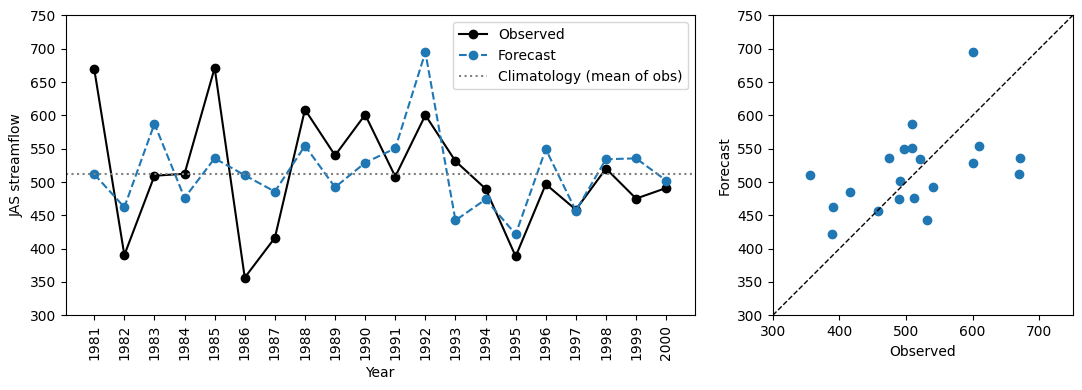

In [2]:
y_hat = np.array([511.7, 462.1, 587.5, 476.1, 535.6, 510.1, 485.6, 554.4, 492.1, 529.0,
                  550.5, 694.8, 442.4, 473.9, 421.6, 549.3, 456.8, 534.2, 535.5, 502.2])  # forecast
y     = np.array([669.3, 390.3, 509.4, 512.4, 671.3, 356.5, 416.2, 608.8, 540.0, 601.1,
                  508.2, 600.4, 531.3, 489.9, 388.3, 496.7, 458.5, 520.2, 475.1, 491.0])  # observed
n = len(y)
years = np.arange(1981, 2001)  # 1981–2000

lim = [300, 750]  # shared streamflow range for both panels

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [2, 1]})
axes[0].plot(years, y, 'ko-', label='Observed'); axes[0].plot(years, y_hat, 'o--', color='tab:blue', label='Forecast')
axes[0].axhline(y.mean(), color='gray', ls=':', label='Climatology (mean of obs)')
axes[0].set_xlabel('Year'); axes[0].set_ylabel('JAS streamflow'); axes[0].legend()
axes[0].set_xticks(years); axes[0].tick_params(axis='x', rotation=90)  # label every year
axes[0].set_ylim(lim)
axes[1].scatter(y, y_hat); axes[1].plot(lim, lim, 'k--', lw=1); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel('Observed'); axes[1].set_ylabel('Forecast'); axes[1].set_aspect('equal')
plt.tight_layout(); plt.show()

### Bias and accuracy

**Bias** compares the *averages*:

$$
\text{Bias} = \bar{\hat{y}} - \bar{y}
$$

**Accuracy** compares forecasts and observations *pair by pair*:

$$
MAE = \frac{1}{n}\sum_{t=1}^{n} |\hat{y}_t - y_t|, \qquad
RMSE = \sqrt{\frac{1}{n}\sum_{t=1}^{n} (\hat{y}_t - y_t)^2}
$$

RMSE ≥ MAE always; the gap grows when a few large errors dominate.

**Range of values**

| Score | Best | Worst | Notes |
|---|---|---|---|
| Bias | 0 | $\pm\infty$ | sign matters: $>0$ over-forecast, $<0$ under-forecast; a bias of 0 does **not** mean the forecasts are accurate (errors can cancel) |
| MAE | 0 | $+\infty$ | no upper bound; same units as the variable |
| RMSE | 0 | $+\infty$ | no upper bound; same units as the variable; $RMSE \ge MAE$ |

None of these has a built-in reference, so a value like "RMSE = 50" says nothing until you compare it with the RMSE of climatology or persistence (next section).


In [3]:
err = y_hat - y
print(f'Bias (fcst - obs) : {err.mean():8.2f}')
print(f'MAE               : {np.abs(err).mean():8.2f}')
print(f'RMSE              : {np.sqrt(np.mean(err**2)):8.2f}')
print(f'Std. dev. of obs  : {y.std(ddof=1):8.2f}   <- RMSE of the climatological forecast (roughly)')

Bias (fcst - obs) :     3.53
MAE               :    64.59
RMSE              :    77.91
Std. dev. of obs  :    87.46   <- RMSE of the climatological forecast (roughly)


### Skill: compare with a reference

A forecast is only useful if it beats something simple. The general skill-score form (Wilks Eq. 8.4):

$$
SS_{ref} = \frac{A - A_{ref}}{A_{perf} - A_{ref}}
$$

With MSE as the accuracy measure ($A_{perf}=0$):

$$
SS_{clim} = 1 - \frac{MSE}{MSE_{clim}}, \qquad SS_{pers} = 1 - \frac{MSE}{MSE_{pers}}
$$

**Range of values**

| Value | Meaning |
|---|---|
| $SS = 1$ | perfect forecast ($MSE = 0$) — the best possible |
| $0 < SS < 1$ | better than the reference |
| $SS = 0$ | no better than the reference (climatology or persistence) |
| $SS < 0$ | **worse** than the reference; there is no lower bound ($-\infty$), a very bad forecast can score, e.g., $-3$ |

So the scale is asymmetric: "1 is perfect, 0 is the reference, negative is worse than doing nothing clever".


In [4]:
mse = np.mean(err**2)
mse_clim = np.mean((y.mean() - y)**2)          # climatology: forecast the long-term mean every year
mse_pers = np.mean((y[:-1] - y[1:])**2)        # persistence: forecast last year's value
mse_pers_f = np.mean((y_hat[1:] - y[1:])**2)   # forecast MSE on the same 19 years, for a fair comparison
print(f'SS vs climatology : {1 - mse / mse_clim:.3f}')
print(f'SS vs persistence : {1 - mse_pers_f / mse_pers:.3f}')

SS vs climatology : 0.165
SS vs persistence : 0.697


### Correlation: Pearson and Spearman

Pearson's $r$ measures the strength of the *linear* association. It is insensitive to bias and to the amplitude of the forecast (a forecast that is always exactly half the observation has $r = 1$), so it should never be reported alone.

$$
r = \frac{\sum(\hat{y}_t-\bar{\hat{y}})(y_t-\bar{y})}{\sqrt{\sum(\hat{y}_t-\bar{\hat{y}})^2}\sqrt{\sum(y_t-\bar{y})^2}}
$$

When one or two extreme years dominate, or the data are far from normal, also compute the **Spearman rank correlation**: the Pearson correlation between the *ranks*. Without ties,

$$
r_s = 1 - \frac{6\sum_{t} d_t^2}{n(n^2-1)}, \qquad d_t = \text{rank}(\hat{y}_t) - \text{rank}(y_t)
$$

**Range of values.** Both $r$ and $r_s$ lie in $[-1, 1]$.

| Value | Meaning |
|---|---|
| $+1$ | perfect (linear / monotonic) association — the best |
| $0$ | no association; the forecast carries no information about the ordering of the outcomes |
| $-1$ | perfect *inverse* association: the forecast is systematically wrong in direction |

Note that a correlation of 1 does **not** mean a perfect forecast (bias and amplitude errors are invisible to $r$), and for forecast verification a negative correlation is "worse than useless": the forecast would be informative only if you flipped it.


In [5]:
r_pearson = np.corrcoef(y_hat, y)[0, 1]

# Spearman by hand: rank, then Pearson of ranks (or the d^2 shortcut)
rk_f, rk_o = stats.rankdata(y_hat), stats.rankdata(y)
d = rk_f - rk_o
r_spearman_manual = 1 - 6 * np.sum(d**2) / (n * (n**2 - 1))
r_spearman_scipy = stats.spearmanr(y_hat, y).statistic

print(f'Pearson  r   : {r_pearson:.3f}')
print(f'Spearman r_s : {r_spearman_manual:.3f} (manual)  {r_spearman_scipy:.3f} (scipy)')
print()
print(pd.DataFrame({'obs': y, 'fcst': y_hat, 'rank_obs': rk_o, 'rank_fcst': rk_f, 'd': d}, index=pd.Index(years, name='year')))

Pearson  r   : 0.464
Spearman r_s : 0.484 (manual)  0.484 (scipy)

        obs   fcst  rank_obs  rank_fcst     d
year                                         
1981  669.3  511.7      19.0       11.0  -8.0
1982  390.3  462.1       3.0        4.0   1.0
1983  509.4  587.5      11.0       19.0   8.0
1984  512.4  476.1      12.0        6.0  -6.0
1985  671.3  535.6      20.0       15.0  -5.0
1986  356.5  510.1       1.0       10.0   9.0
1987  416.2  485.6       4.0        7.0   3.0
1988  608.8  554.4      18.0       18.0   0.0
1989  540.0  492.1      15.0        8.0  -7.0
1990  601.1  529.0      17.0       12.0  -5.0
1991  508.2  550.5      10.0       17.0   7.0
1992  600.4  694.8      16.0       20.0   4.0
1993  531.3  442.4      14.0        2.0 -12.0
1994  489.9  473.9       7.0        5.0  -2.0
1995  388.3  421.6       2.0        1.0  -1.0
1996  496.7  549.3       9.0       16.0   7.0
1997  458.5  456.8       5.0        3.0  -2.0
1998  520.2  534.2      13.0       13.0   0.0
1999  475.1  

> **Question:** 1992 has the largest forecast (694.8). Remove 1992 and recompute Pearson and Spearman correlations. Which one changes more, and why?

<!-- Answer: Pearson drops noticeably because 1992 is an influential point that pulls the regression line; Spearman changes little because removing one rank barely alters the ordering of the others. -->

In [6]:
# Your code here
keep = years != 1992

## Part 2. Deterministic categorical forecasts

### 2.1 The 2×2 contingency table

For a yes/no event, every forecast–observation pair falls into one of four cells:

| | Observed: yes | Observed: no |
|---|---|---|
| **Forecast: yes** | $a$ = hits | $b$ = false alarms |
| **Forecast: no** | $c$ = misses | $d$ = correct negatives |

Dividing by $n = a+b+c+d$ gives the **joint probabilities** $p(\hat{y}, y)$; the row and column sums are the marginal distributions of forecasts $p(\hat{y})$ and observations $p(y)$.

We use the classic Finley (1884) tornado forecasts (Wilks, Table 8.3a): $a=28,\; b=72,\; c=23,\; d=2680$.

In [7]:
a, b, c, d = 28, 72, 23, 2680
n2 = a + b + c + d
table = pd.DataFrame([[a, b], [c, d]], index=['Fcst yes', 'Fcst no'], columns=['Obs yes', 'Obs no'])
print(table); print()
print('Joint probabilities p(fcst, obs):'); print((table / n2).round(4)); print()
print('Marginal p(obs):  ', (table.sum(axis=0) / n2).round(4).values)
print('Marginal p(fcst): ', (table.sum(axis=1) / n2).round(4).values)

          Obs yes  Obs no
Fcst yes       28      72
Fcst no        23    2680

Joint probabilities p(fcst, obs):
          Obs yes  Obs no
Fcst yes    0.010   0.026
Fcst no     0.008   0.956

Marginal p(obs):   [0.018 0.982]
Marginal p(fcst):  [0.036 0.964]


### Scores from the 2×2 table

| Score | Formula | Range | Perfect | Worst | Meaning |
|---|---|---|---|---|---|
| Proportion correct | $PC = \frac{a+d}{n}$ | 0 – 1 | 1 | 0 | fraction of all forecasts that were right |
| Hit rate (POD) | $H = \frac{a}{a+c}$ | 0 – 1 | 1 | 0 | fraction of observed events that were forecast |
| False alarm ratio | $FAR = \frac{b}{a+b}$ | 0 – 1 | 0 | 1 | fraction of "yes" forecasts that were wrong |
| False alarm rate | $F = \frac{b}{b+d}$ | 0 – 1 | 0 | 1 | fraction of non-events that were forecast "yes" |
| Threat score (CSI) | $TS = \frac{a}{a+b+c}$ | 0 – 1 | 1 | 0 | PC without the (easy) correct negatives |
| Frequency bias | $B = \frac{a+b}{a+c}$ | 0 – $\infty$ | 1 | 0 or $\infty$ | B > 1: event over-forecast; B < 1: under-forecast |

Two cautions on reading "best" and "worst":
- $H$, $FAR$, $F$ and $B$ are **not accuracy measures on their own**: "always yes" gives the perfect $H = 1$ but also the worst $F = 1$; "always no" gives the perfect $F = 0$ but the worst $H = 0$. They must be read in pairs.
- $B$ is not a score at all but a measure of calibration of the *frequency* of forecasts; $B = 1$ only says the event was forecast as often as it occurred, not that the right years were picked.


Note the two different "false alarm" quantities: **FAR** is conditioned on the forecast, **F** on the observation.

In [8]:
def scores_2x2(a, b, c, d):
    n = a + b + c + d
    return pd.Series({'PC': (a + d) / n, 'H (hit rate)': a / (a + c), 'FAR': b / (a + b),
                      'F (false alarm rate)': b / (b + d), 'TS': a / (a + b + c), 'Bias': (a + b) / (a + c)})

print(scores_2x2(a, b, c, d))

PC                      0.966
H (hit rate)            0.549
FAR                     0.720
F (false alarm rate)    0.026
TS                      0.228
Bias                    1.961
dtype: float64


### Why PC is not enough: the Finley affair

Gilbert (1884) noticed that a forecaster who **never** forecasts a tornado scores a *higher* PC than Finley.

In [9]:
print(f'Finley      PC = {(a + d) / n2:.4f}')
print(f'Always "no" PC = {(b + d) / n2:.4f}')

Finley      PC = 0.9661
Always "no" PC = 0.9818


### 2.2 Skill scores for contingency tables

The fix is to measure accuracy **relative to a reference** (Wilks Eq. 8.4): $SS = \dfrac{A - A_{ref}}{A_{perf} - A_{ref}}$.

**Heidke Skill Score (HSS)** uses PC as the accuracy measure and *random forecasts that are statistically independent of the observations* (but with the same marginal frequencies) as the reference. For the 2×2 case the chance of a correct "yes" is $p(\hat{y}=1)\,p(y=1)$ and of a correct "no" is $p(\hat{y}=0)\,p(y=0)$, which leads to

$$
HSS = \frac{2(ad - bc)}{(a+c)(c+d) + (a+b)(b+d)}
$$

**Peirce Skill Score (PSS)** uses the *observed* marginal distribution for the reference as well (unbiased random forecasts), and reduces to

$$
PSS = \frac{ad - bc}{(a+c)(b+d)} = H - F
$$

**Range of values.** Both scores lie in $[-1, 1]$:

| Value | Meaning |
|---|---|
| $1$ | perfect forecast ($b = c = 0$) — the best |
| $0$ | no better than random forecasts with the same marginal frequencies; constant forecasts ("always yes", "always no") also score 0 |
| $< 0$ | worse than random |
| $-1$ | the worst: every forecast is wrong ($a = d = 0$) — a perfectly *inverted* forecast |

Unlike $PC$, these scores cannot be gamed by always forecasting the climatologically likely outcome: that strategy gives exactly 0.

In [10]:
def skill_2x2(a, b, c, d):
    n = a + b + c + d
    # HSS via the general form: (PC - PC_ref) / (1 - PC_ref)
    pc = (a + d) / n
    pc_ref = ((a + b) / n) * ((a + c) / n) + ((c + d) / n) * ((b + d) / n)
    hss_general = (pc - pc_ref) / (1 - pc_ref)
    hss = 2 * (a * d - b * c) / ((a + c) * (c + d) + (a + b) * (b + d))
    pss = (a * d - b * c) / ((a + c) * (b + d))
    return pd.Series({'PC_ref (random)': pc_ref, 'HSS (general form)': hss_general,
                      'HSS (closed form)': hss, 'PSS = H - F': pss})

print('Finley:'); print(skill_2x2(a, b, c, d)); print()
print('Always "no":'); print(skill_2x2(0, 0, a + c, b + d).fillna(0))

Finley:
PC_ref (random)       0.947
HSS (general form)    0.355
HSS (closed form)     0.355
PSS = H - F           0.523
dtype: float64

Always "no":
PC_ref (random)       0.982
HSS (general form)    0.000
HSS (closed form)     0.000
PSS = H - F           0.000
dtype: float64


> **Question:** What is the PSS of a forecaster who always says "yes"? Why do "always yes" and "always no" get the same PSS?

<!-- Answer: always yes: H = 1, F = 1, PSS = 0. Neither constant forecast discriminates between events and non-events, so both have zero skill. PSS depends only on H and F, i.e. on discrimination, not on how often the event is forecast. -->

### 2.3 Multicategory forecasts: the Heidke score for terciles

Seasonal outlooks are usually **tercile categories** (below / near / above normal). The IRI-style **Heidke score** counts hits against the number expected by chance:

$$
\text{Heidke score (\%)} = 100 \times \frac{\#\text{Hits} - \#\text{Expected}}{\#\text{Total} - \#\text{Expected}}, \qquad \#\text{Expected} = \frac{\#\text{Total}}{3}
$$

Example: 15 stations, all forecast "above", 12 observed above → $100 \times (12 - 5)/(15 - 5) = 70$.

**Range of values**

| Value | Meaning |
|---|---|
| $100$ | all forecasts hit — the best |
| $0$ | hits equal the number expected by chance (one third) |
| $< 0$ | fewer hits than chance |
| $-50$ | the worst: zero hits, $100 \times (0 - T/3)/(T - T/3) = -50$ |

The scale is asymmetric: the "good" side runs from 0 to 100 but the "bad" side only from 0 to $-50$. In the example above, 15 stations with 12 hits give 70; with 5 hits (pure chance) it would be 0, and with 0 hits $-50$.


In [11]:
def heidke_percent(n_hits, n_total, n_cat=3):
    expected = n_total / n_cat
    return 100 * (n_hits - expected) / (n_total - expected)

print(f'Example: Heidke score = {heidke_percent(12, 15):.0f} %')

Example: Heidke score = 70 %


Now apply it to the Koka forecasts. We define categories using the terciles of the **observed** record and classify both $y$ and $\hat{y}$.

For a general $K\times K$ table with joint relative frequencies $p(\hat{y}_i, y_j)$ (Wilks Eqs. 8.22–8.23):

$$
HSS = \frac{\sum_i p(\hat{y}_i,y_i) - \sum_i p(\hat{y}_i)\,p(y_i)}{1 - \sum_i p(\hat{y}_i)\,p(y_i)}, \qquad
PSS = \frac{\sum_i p(\hat{y}_i,y_i) - \sum_i p(\hat{y}_i)\,p(y_i)}{1 - \sum_i p(y_i)^2}
$$

The Heidke score in % above is a simplified HSS that assumes the reference forecast hits exactly $1/3$ of the time.

**Range of values**

| Score | Best | Random reference | Worst |
|---|---|---|---|
| $HSS$ | 1 | 0 | $-\dfrac{\sum_i p(\hat y_i)p(y_i)}{1-\sum_i p(\hat y_i)p(y_i)}$; with three equally likely categories this is $-0.5$ (the same $-50$ % as the Heidke score above) |
| $PSS$ | 1 | 0 | $-\dfrac{\sum_i p(y_i)^2}{1-\sum_i p(y_i)^2}$; with three equally likely categories also $-0.5$ |

In both cases 1 means every forecast landed in the observed category and 0 means the number of hits is exactly what random forecasts would produce. The worst value is reached when the forecast *never* hits; it is only $-1$ in the 2×2 case, and closer to 0 when there are more categories (because a random forecast already misses more often).


In [12]:
cats = ['Below', 'Near', 'Above']
terc = np.percentile(y, [100/3, 200/3])
y_cat, yhat_cat = np.digitize(y, terc), np.digitize(y_hat, terc)       # 0, 1, 2

ct = pd.crosstab(pd.Categorical(yhat_cat, [0, 1, 2]), pd.Categorical(y_cat, [0, 1, 2]), dropna=False)
ct.index = ['Fcst ' + k for k in cats]; ct.columns = ['Obs ' + k for k in cats]
print('Terciles of observed flow:', terc.round(1)); print(ct); print()

def skill_multicat(ct):
    p = ct.to_numpy(float); p = p / p.sum()      # joint probabilities (plain ndarray, not DataFrame)
    pf, po = p.sum(axis=1), p.sum(axis=0)
    pc, pc_ref = np.trace(p), np.sum(pf * po)
    return pd.Series({'PC': pc, 'HSS': (pc - pc_ref) / (1 - pc_ref), 'PSS': (pc - pc_ref) / (1 - np.sum(po**2))})

hits = np.trace(ct.values)
print(f'Hits = {hits} of {n};  Heidke score = {heidke_percent(hits, n):.1f} %')
print(skill_multicat(ct))

Terciles of observed flow: [490.3 527.6]
            Obs Below  Obs Near  Obs Above
Fcst Below          5         1          1
Fcst Near           1         1          2
Fcst Above          1         4          4

Hits = 10 of 20;  Heidke score = 25.0 %
PC     0.500
HSS    0.242
PSS    0.241
dtype: float64


> **Question:** The Heidke score (and HSS) only use *which* category was forecast, not how confident the forecast was. Why is this "a big weakness" for seasonal forecasts? What kind of score fixes it? (→ Part 3)

## Part 3. Probabilistic categorical forecasts

A tercile forecast is really a probability vector, e.g. (below, near, above) = (20 %, 30 %, 50 %). Probabilistic forecasts can "never be wrong" — so we need scores that reward putting *more* probability on what happened, and penalize overconfidence.

### 3.1 Ranked Probability Score

With $K$ ordered categories, forecast probabilities $f_k$ and observation $o_k$ (1 in the observed category, 0 elsewhere),

$$
RPS = \sum_{k=1}^{K}\left(\sum_{j=1}^{k} f_j - \sum_{j=1}^{k} o_j\right)^2
$$

The **cumulative** sums mean that probability placed *two* categories away from the observation is penalized more than probability placed in the neighbouring category. $RPS = 0$ only when 100 % was given to the observed category.

**A worked example.** Forecast (below, near, above) = (0.2, 0.3, 0.5); the season turns out **above** normal, so $o = (0, 0, 1)$.

| | Below | Near | Above |
|---|---|---|---|
| Forecast $f_k$ | 0.2 | 0.3 | 0.5 |
| Cumulative $\sum f_j$ | 0.2 | 0.5 | 1.0 |
| Observed $o_k$ | 0 | 0 | 1 |
| Cumulative $\sum o_j$ | 0 | 0 | 1 |
| Difference | 0.2 | 0.5 | 0 |

$$
RPS = 0.2^2 + 0.5^2 + 0^2 = 0.04 + 0.25 + 0 = 0.29
$$

Read it as "how much probability was still *below* the outcome at each step". Climatology (1/3, 1/3, 1/3) gives $RPS = (1/3)^2 + (2/3)^2 = 0.556$, so our forecast did better than climatology.

**Why cumulative?** Compare two forecasts that both give 50 % to the observed "above" category:

- (0, **0.5**, 0.5): the other 50 % is one category away → cumulative (0, 0.5, 1.0) → $RPS = 0 + 0.25 + 0 = 0.25$
- (**0.5**, 0, 0.5): the other 50 % is two categories away → cumulative (0.5, 0.5, 1.0) → $RPS = 0.25 + 0.25 + 0 = 0.50$

A plain squared error on $f_k$ alone would score these two forecasts identically; RPS correctly says the second one is worse because it was "further" from what happened.

$$
RPSS = 1 - \frac{\overline{RPS}}{\overline{RPS}_{ref}}, \qquad \text{ref} = (1/3, 1/3, 1/3)\ \text{climatology}
$$

**Range of values**

| Score | Best | Climatology | Worst |
|---|---|---|---|
| $RPS$ (single forecast) | 0 — 100 % on the observed category | 0.556 for three terciles | $K - 1 = 2$ for three terciles: 100 % on the category *farthest* from the outcome, e.g. $f = (1, 0, 0)$ when "above" occurs → cumulative difference $(1, 1, 0)$ → $RPS = 1 + 1 + 0 = 2$ |
| $RPSS$ | 1 | 0 | negative, **no lower bound**; the single-forecast worst case above gives $1 - 2/0.556 = -2.6$ |

Like all skill scores, RPSS is asymmetric: it can gain at most 1 point over climatology but can lose several. This is what makes overconfident forecasts dangerous (see the question below): the occasional $-2.6$ wipes out many small gains.

In [13]:
def rps(f, o):
    '''f: (n, K) forecast probabilities, o: (n, K) one-hot observations. Returns (n,) RPS.'''
    f, o = np.atleast_2d(f), np.atleast_2d(o)
    return np.sum((np.cumsum(f, axis=1) - np.cumsum(o, axis=1))**2, axis=1)

def rpss(f, o, ref=None):
    ref = np.full_like(np.atleast_2d(f), 1 / f.shape[-1]) if ref is None else ref
    return 1 - rps(f, o).mean() / rps(ref, o).mean()

# Sanity checks: observation = "above"
o_above = np.array([[0, 0, 1]])
print('RPS perfect (0,0,1)         =', rps([[0, 0, 1]], o_above))
print('RPS climatology (1/3,1/3,1/3)=', rps([[1/3, 1/3, 1/3]], o_above), '(= 1/9 + 4/9 = 0.556)')
print('RPS wrong & confident (1,0,0)=', rps([[1, 0, 0]], o_above))
print('RPS neighbour (0,1,0)        =', rps([[0, 1, 0]], o_above), ' <- less penalized than (1,0,0)')

RPS perfect (0,0,1)         = [0]
RPS climatology (1/3,1/3,1/3)= [0.556] (= 1/9 + 4/9 = 0.556)
RPS wrong & confident (1,0,0)= [2]
RPS neighbour (0,1,0)        = [1]  <- less penalized than (1,0,0)


### Reproducing the RPSS table

Observation is "above". Compute RPSS for each forecast probability triplet against climatology.

In [14]:
triplets = np.array([[100, 0, 0], [90, 10, 0], [80, 15, 5], [70, 25, 5], [60, 30, 10], [50, 30, 20],
                     [40, 35, 25], [33.3, 33.3, 33.4], [25, 35, 40], [20, 30, 50], [10, 30, 60],
                     [5, 25, 70], [5, 15, 80], [0, 10, 90], [0, 0, 100]]) / 100
tab = pd.DataFrame(triplets * 100, columns=['Below %', 'Near %', 'Above %']).astype(int)
tab['RPS'] = rps(triplets, np.tile(o_above, (len(triplets), 1)))
tab['RPSS'] = [rpss(f[None, :], o_above) for f in triplets]
print(tab.round(2).to_string(index=False))

 Below %  Near %  Above %  RPS  RPSS
     100       0        0 2.00 -2.60
      90      10        0 1.81 -2.26
      80      15        5 1.54 -1.78
      70      25        5 1.39 -1.51
      60      30       10 1.17 -1.11
      50      30       20 0.89 -0.60
      40      35       25 0.72 -0.30
      33      33       33 0.55  0.00
      25      35       40 0.42  0.24
      20      30       50 0.29  0.48
      10      30       60 0.17  0.69
       5      25       70 0.09  0.83
       5      15       80 0.04  0.92
       0      10       90 0.01  0.98
       0       0      100 0.00  1.00


> **Question:** A forecaster "knows" the true probabilities are (10, 30, 60). Over many years with those odds, would issuing (0, 0, 100) every time give a better or worse average RPSS than issuing (10, 30, 60)? Check it with a simulation.

<!-- Answer: worse. RPS is a proper score: the expected RPS is minimized by issuing the true probabilities. Over-confident forecasts win when the event happens but lose heavily (RPSS = -2.6) when it does not. -->

In [15]:
rng = np.random.default_rng(1)
true_p = np.array([0.10, 0.30, 0.60])
obs_cat = rng.choice(3, size=5000, p=true_p)
onehot = np.eye(3)[obs_cat]
for name, f in {'honest (10,30,60)': true_p, 'overconfident (0,0,100)': np.array([0, 0, 1.0]),
                'hedged (20,30,50)': np.array([0.2, 0.3, 0.5])}.items():
    print(f'{name:26s} mean RPSS = {rpss(np.tile(f, (len(obs_cat), 1)), onehot):.3f}')

honest (10,30,60)          mean RPSS = 0.271
overconfident (0,0,100)    mean RPSS = -0.111
hedged (20,30,50)          mean RPSS = 0.229


### 3.2 Likelihood score

The likelihood score is the geometric mean of the probabilities that were assigned to the categories that *actually occurred*:

$$
L = \left(\prod_{t=1}^{n} f_{t,\,o_t}\right)^{1/n}
$$

It ignores how probability was spread over the categories that did **not** occur. The only question it asks is: *"how much probability did you give to what actually happened?"*

**A worked example** (the same five forecasts as the code cell below):

| Forecast (below, near, above) | Observed | Probability given to the observed category |
|---|---|---|
| (0.45, 0.35, 0.20) | near | **0.35** |
| (0.33, 0.33, 0.33) | near | **0.33** |
| (0.40, 0.33, 0.27) | below | **0.40** |
| (0.15, 0.30, 0.55) | above | **0.55** |
| (0.20, 0.40, 0.40) | near | **0.40** |

$$
L = (0.35 \times 0.33 \times 0.40 \times 0.55 \times 0.40)^{1/5} \approx 0.40
$$

**Why a geometric mean?** Because it is a *product*, a single near-zero probability drags the whole score down: if one year the forecast gave only 1 % to what happened, no amount of success in the other years can rescue $L$. This makes the likelihood score very harsh on **overconfidence** (saying "this will never happen" and being wrong). The arithmetic mean of the same five numbers (0.41) would barely register such a mistake.

**Range of values.** $L$ lies in $[0, 1]$. A perfect forecast gives 100 % to what happened every year, so $L = 1$ (the best). Climatology (1/3, 1/3, 1/3) always gives 1/3 to the observed category, so $L_{clim} = 1/3$. The worst value is $L = 0$, and it is reached as soon as a *single* forecast gave 0 % to the category that occurred — regardless of how good the other $n-1$ forecasts were. Scaling so that climatology = 0 % and perfect = 100 %:

$$
\frac{L - 1/3}{1 - 1/3} \approx \frac{0.40 - 0.33}{0.67} \approx 10\ \%
$$

so the five forecasts above are only slightly better than climatology. On this scaled version perfect = 100 %, climatology = 0 %, and the worst value is $(0 - 1/3)/(2/3) = -50$ %, the same asymmetric scale as the Heidke score.

**RPS vs. likelihood score.** RPS also penalizes how *far* the misplaced probability sits from the outcome; the likelihood score looks only at the probability on the outcome itself, but punishes one big miss multiplicatively.

In [16]:
# Example: five tercile forecasts; observed category marked
fcst5 = np.array([[45, 35, 20], [33, 33, 33], [40, 33, 27], [15, 30, 55], [20, 40, 40]]) / 100
obs5  = np.array([1, 1, 0, 2, 1])                  # observed category index (0=below, 1=near, 2=above)
p_obs = fcst5[np.arange(5), obs5]
L = np.prod(p_obs) ** (1 / 5)                       # geometric mean  (= exp(mean(log p)))
print('Probabilities given to the observed category:', p_obs)
print(f'Likelihood score L = {L:.3f};  scaled = {(L - 1/3) / (1 - 1/3) * 100:.1f} %')

Probabilities given to the observed category: [0.35 0.33 0.4  0.55 0.4 ]
Likelihood score L = 0.399;  scaled = 9.9 %


## Part 4. Verifying an ensemble forecast system

To look at reliability, ROC and the full distribution we need many probabilistic forecasts. We **simulate a 40-year hindcast** of a seasonal reservoir inflow with a 20-member ensemble, so that we can control the skill, bias and spread and watch how each score responds:

- Observation: $y_t = \mu + \sigma\,(\rho\, s_t + \sqrt{1-\rho^2}\, \varepsilon_t)$ — $s_t$ is a predictable *signal* (snowpack, ENSO, soil moisture), $\varepsilon_t$ is unpredictable.
- Ensemble member $m$: $f_{t,m} = \mu + \sigma\,(\rho\, s_t + \beta) + \sigma\sqrt{1-\rho^2}\;\gamma\, \eta_{t,m}$

| Knob | Meaning | Effect |
|---|---|---|
| `rho` | correlation between signal and outcome | **skill** (ρ = 0: none) |
| `beta` | bias, in units of σ | systematic error |
| `gamma` | spread factor | γ = 1 well calibrated; γ < 1 **overconfident**; γ > 1 underconfident |

Come back and change the knobs after running through the section once.

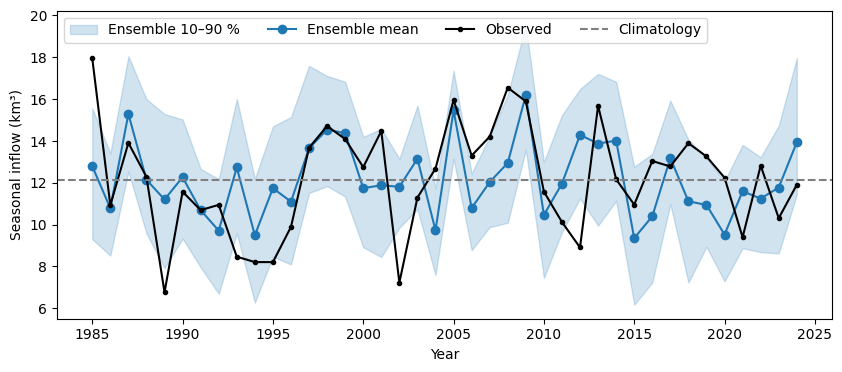

In [17]:
def make_hindcast(n_years=40, n_members=20, mu=12.0, sigma=3.0, rho=0.6, beta=0.0, gamma=1.0, seed=2841):
    '''Observed seasonal inflow (km3) and an M-member ensemble hindcast with known structure.'''
    rng = np.random.default_rng(seed)
    years = np.arange(2025 - n_years, 2025)
    s, eps = rng.standard_normal(n_years), rng.standard_normal(n_years)
    obs = mu + sigma * (rho * s + np.sqrt(1 - rho**2) * eps)
    eta = rng.standard_normal((n_years, n_members))
    ens = mu + sigma * (rho * s + beta)[:, None] + sigma * np.sqrt(1 - rho**2) * gamma * eta
    return years, obs, ens

years, obs, ens = make_hindcast(rho=0.6, beta=0.0, gamma=1.0)
fmean = ens.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(years, np.percentile(ens, 10, axis=1), np.percentile(ens, 90, axis=1), color='tab:blue', alpha=.2, label='Ensemble 10–90 %')
ax.plot(years, fmean, 'o-', color='tab:blue', label='Ensemble mean'); ax.plot(years, obs, 'k.-', label='Observed')
ax.axhline(obs.mean(), color='gray', ls='--', label='Climatology')
ax.set_ylabel('Seasonal inflow (km³)'); ax.set_xlabel('Year'); ax.legend(ncol=4, loc='upper left'); plt.show()

### 4.1 From ensemble to probabilities → RPSS

Tercile probabilities are the fraction of members in each category. (Thresholds from the observed record.)

In [18]:
terc_e = np.percentile(obs, [100/3, 200/3])
obs_cat_e = np.digitize(obs, terc_e)
ens_cat = np.digitize(ens, terc_e)                                           # (n, M)
p_cat = np.stack([(ens_cat == k).mean(axis=1) for k in range(3)], axis=1)    # (n, 3)
onehot_e = np.eye(3)[obs_cat_e]

print('First five forecasts (below, near, above):'); print(np.c_[years[:5], p_cat[:5]])
print(f'\nRPSS vs climatology = {rpss(p_cat, onehot_e):.3f}')

# Deterministic view for comparison: category of the ensemble mean
ct_e = pd.crosstab(pd.Categorical(np.digitize(fmean, terc_e), [0,1,2]), pd.Categorical(obs_cat_e, [0,1,2]), dropna=False)
print(f'Heidke score (ensemble-mean category) = {heidke_percent(np.trace(ct_e.values), len(obs)):.1f} %')

First five forecasts (below, near, above):
[[1985.      0.2     0.3     0.5 ]
 [1986.      0.55    0.3     0.15]
 [1987.      0.      0.2     0.8 ]
 [1988.      0.4     0.25    0.35]
 [1989.      0.4     0.45    0.15]]

RPSS vs climatology = 0.108
Heidke score (ensemble-mean category) = 13.8 %


### 4.2 Reliability and the Brier score

Take a single event, "above-normal inflow", with forecast probability $p_t$ and outcome $o_t\in\{0,1\}$.

**Reliability**: among all the times we said 70 %, did it happen 70 % of the time? Bin the forecasts by probability and compare the mean forecast probability $p_i$ in each bin with the observed frequency $\bar{o}_i$. On the **reliability diagram** a reliable system lies on the 1:1 line; a curve flatter than 1:1 means **overconfident** (events happen less often than claimed at high probabilities), steeper means underconfident. The inset histogram shows **sharpness** — how often the system commits to high or low probabilities.

The **Brier score** is the RPS for two categories,

$$
BS = \frac{1}{n}\sum_{t}(p_t - o_t)^2, \qquad BSS = 1 - \frac{BS}{BS_{clim}}, \quad BS_{clim} = \bar{o}(1-\bar{o})
$$

and Murphy (1973) showed it splits into the two attributes just discussed plus a term that depends only on the observations:

$$
BS = \underbrace{\frac{1}{n}\sum_i N_i (p_i - \bar o_i)^2}_{\text{reliability (want small)}}
   - \underbrace{\frac{1}{n}\sum_i N_i (\bar o_i - \bar o)^2}_{\text{resolution (want large)}}
   + \underbrace{\bar o (1 - \bar o)}_{\text{uncertainty}}
$$

**Range of values**

| Quantity | Best | Worst | Notes |
|---|---|---|---|
| $BS$ | 0 (always 100 % on what happened) | 1 (always 100 % on what did *not* happen) | climatology gives $\bar o(1-\bar o)$, at most 0.25 |
| $BSS$ | 1 | $-\infty$ (no lower bound) | 0 = climatology; negative = worse than always forecasting the base rate |
| Reliability term | 0 (every bin on the 1:1 line) | 1 | *smaller* is better |
| Resolution term | $\bar o (1-\bar o)$ = uncertainty (bins perfectly separate events from non-events) | 0 (every bin has the same observed frequency as climatology) | *larger* is better |
| Uncertainty | — | — | fixed by the observations; 0.25 when $\bar o = 0.5$, 0 when the event always or never happens |

So $BSS = (\text{resolution} - \text{reliability})/\text{uncertainty}$: a forecast beats climatology only if its resolution exceeds its reliability penalty.


#### Reading the reliability diagram: one table row = one point

The question is: **when we forecast a probability, does the event happen that often?**

Here the event is **above-normal seasonal inflow**: inflow is at or above the upper tercile of the observed record (about **13.26 km³**). Each year has 20 ensemble members. If 14 members meet that inflow threshold, the forecast probability for that year is $p = 14/20 = 0.70$. The observed outcome is $o = 1$ if the event happened, and $o = 0$ otherwise.

To draw the reliability diagram, group the **40 years** by their forecast probability. In each group, average the forecast probabilities for the x-coordinate, and count how often the event actually happened for the y-coordinate.

| Forecast probability bin | Years, N | x: mean forecast probability | Years with the event | y: observed frequency |
|---|---:|---:|---:|---:|
| `[0.0, 0.2)` | 15 | 0.09 | 2 | 2/15 = 0.13 |
| `[0.2, 0.4)` | 10 | 0.29 | 3 | 3/10 = 0.30 |
| `[0.4, 0.6)` | 7 | 0.45 | 3 | 3/7 = 0.43 |
| `[0.6, 0.8)` | 4 | 0.70 | 2 | 2/4 = 0.50 |
| `[0.8, 1.0]` | 4 | 0.84 | 4 | 4/4 = 1.00 |

Values are rounded to two decimal places. A bin includes its lower edge and excludes its upper edge; the final bin also includes 1.0. These are the default `make_hindcast()` results (`rho=0.6`, `beta=0`, `gamma=1`, `seed=2841`). Changing the settings changes the table.

**Read two rows aloud:**

- **0.2–0.4 bin:** there are 10 years with an average forecast probability of 0.29. Above-normal inflow occurred in 3 of them, so the observed frequency is $3/10 = 0.30$. Plot the point **(0.29, 0.30)**. The forecast probability and observed frequency agree closely.
- **0.6–0.8 bin:** there are 4 years with an average forecast probability of 0.70. The event occurred in 2 of them, so plot **(0.70, 0.50)**. In this group the forecast probability was higher than the observed frequency. With only 4 years, the estimate is uncertain: one additional event would change the frequency by 0.25.

The dashed diagonal is **x = y**: what we forecast matches how often it happened. A point below it means the forecast probability was too high for that group; a point above it means it was too low. The numbers beside the plotted points are **N (years), not event counts**. The inset bars show how many years fall in each probability group.

Reliability is about **groups of forecasts**, not whether one 70% forecast was right or wrong. The first row is $2/15 = 0.13$: the event happened in 2 of those 15 years.


      N  p_mean  o_freq
bin                    
0    15   0.087   0.133
1    10   0.290   0.300
2     7   0.450   0.429
3     4   0.700   0.500
4     4   0.838   1.000

Reliability               0.008
Resolution                0.064
Uncertainty               0.227
BS (= REL - RES + UNC)    0.171
dtype: float64

BS = 0.1709   BS_clim = 0.2275   BSS = 0.249


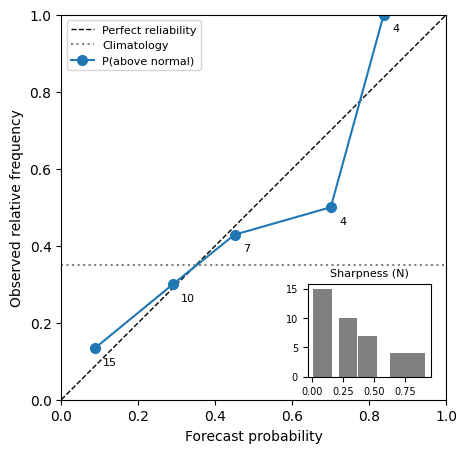

In [19]:
def reliability_table(p, o, bins=np.linspace(0, 1, 6)):
    idx = np.clip(np.digitize(p, bins) - 1, 0, len(bins) - 2)
    rows = [(i, m.sum(), p[m].mean(), o[m].mean()) for i in range(len(bins) - 1) if (m := idx == i).sum() > 0]
    tab = pd.DataFrame(rows, columns=['bin', 'N', 'p_mean', 'o_freq']).set_index('bin')
    n, o_bar = len(p), o.mean()
    rel = np.sum(tab.N * (tab.p_mean - tab.o_freq)**2) / n
    res = np.sum(tab.N * (tab.o_freq - o_bar)**2) / n
    unc = o_bar * (1 - o_bar)
    return tab, pd.Series({'Reliability': rel, 'Resolution': res, 'Uncertainty': unc, 'BS (= REL - RES + UNC)': rel - res + unc})

def reliability_diagram(p, o, ax, label='Forecast'):
    tab, _ = reliability_table(p, o)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect reliability')
    ax.axhline(o.mean(), color='gray', ls=':', label='Climatology')
    ax.plot(tab.p_mean, tab.o_freq, 'o-', ms=7, label=label)
    for _, r in tab.iterrows():
        ax.annotate(int(r.N), (r.p_mean, r.o_freq), textcoords='offset points', xytext=(6, -12), fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.legend(loc='upper left', fontsize=8)
    ax.set_xlabel('Forecast probability'); ax.set_ylabel('Observed relative frequency')
    ins = ax.inset_axes([0.64, 0.06, 0.32, 0.24]); ins.bar(tab.p_mean, tab.N, width=0.15, color='gray')
    ins.set_title('Sharpness (N)', fontsize=8); ins.tick_params(labelsize=7)

p_above = p_cat[:, 2]
o_abv = (obs_cat_e == 2).astype(float)

tab, dec = reliability_table(p_above, o_abv)
bs = np.mean((p_above - o_abv)**2); bs_clim = o_abv.mean() * (1 - o_abv.mean())
print(tab); print(); print(dec)
print(f'\nBS = {bs:.4f}   BS_clim = {bs_clim:.4f}   BSS = {1 - bs / bs_clim:.3f}')

fig, ax = plt.subplots(figsize=(5, 5)); reliability_diagram(p_above, o_abv, ax, 'P(above normal)'); plt.show()

> **Question:** Build an overconfident system (`gamma = 0.4`) and an underconfident one (`gamma = 2.0`) and draw their reliability diagrams side by side. Describe the shapes.

<!-- Answer: gamma = 0.4 gives a curve flatter than the diagonal with most forecasts near 0 or 1 (sharp but unreliable); gamma = 2.0 gives a curve steeper than the diagonal with all forecasts clustered near the climatological frequency (reliable-ish but not sharp). -->

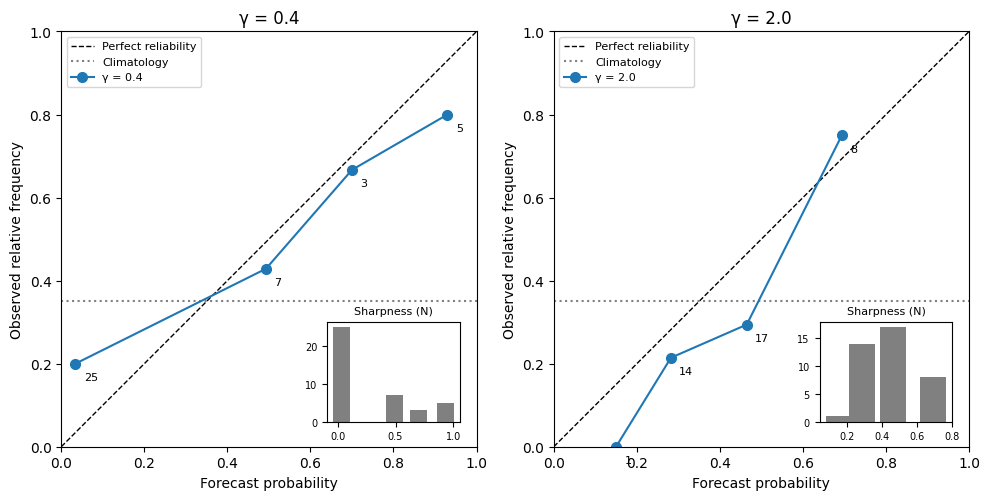

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, g in zip(axes, [0.4, 2.0]):
    _, o_g, e_g = make_hindcast(gamma=g)
    tg = np.percentile(o_g, [100/3, 200/3])
    pg, og = (e_g >= tg[1]).mean(axis=1), (o_g >= tg[1]).astype(float)
    reliability_diagram(pg, og, ax, f'γ = {g}'); ax.set_title(f'γ = {g}')
plt.tight_layout(); plt.show()

### 4.3 ROC curve: discrimination (Wilks 8.4.7)

**ROC** stands for *Receiver Operating Characteristic*. The name comes from WWII radar: the *receiver* had a sensitivity dial, and turning it up caught more enemy aircraft (hits) but also flagged more birds and clouds (false alarms). Sweeping the dial from one end to the other and plotting (false alarm rate, hit rate) gave the *operating characteristic* of that receiver — the full menu of trade-offs it could deliver. The same idea later spread to signal-detection psychology, medical diagnostics and machine learning. For a forecast, the "dial" is the decision threshold $p^\ast$.

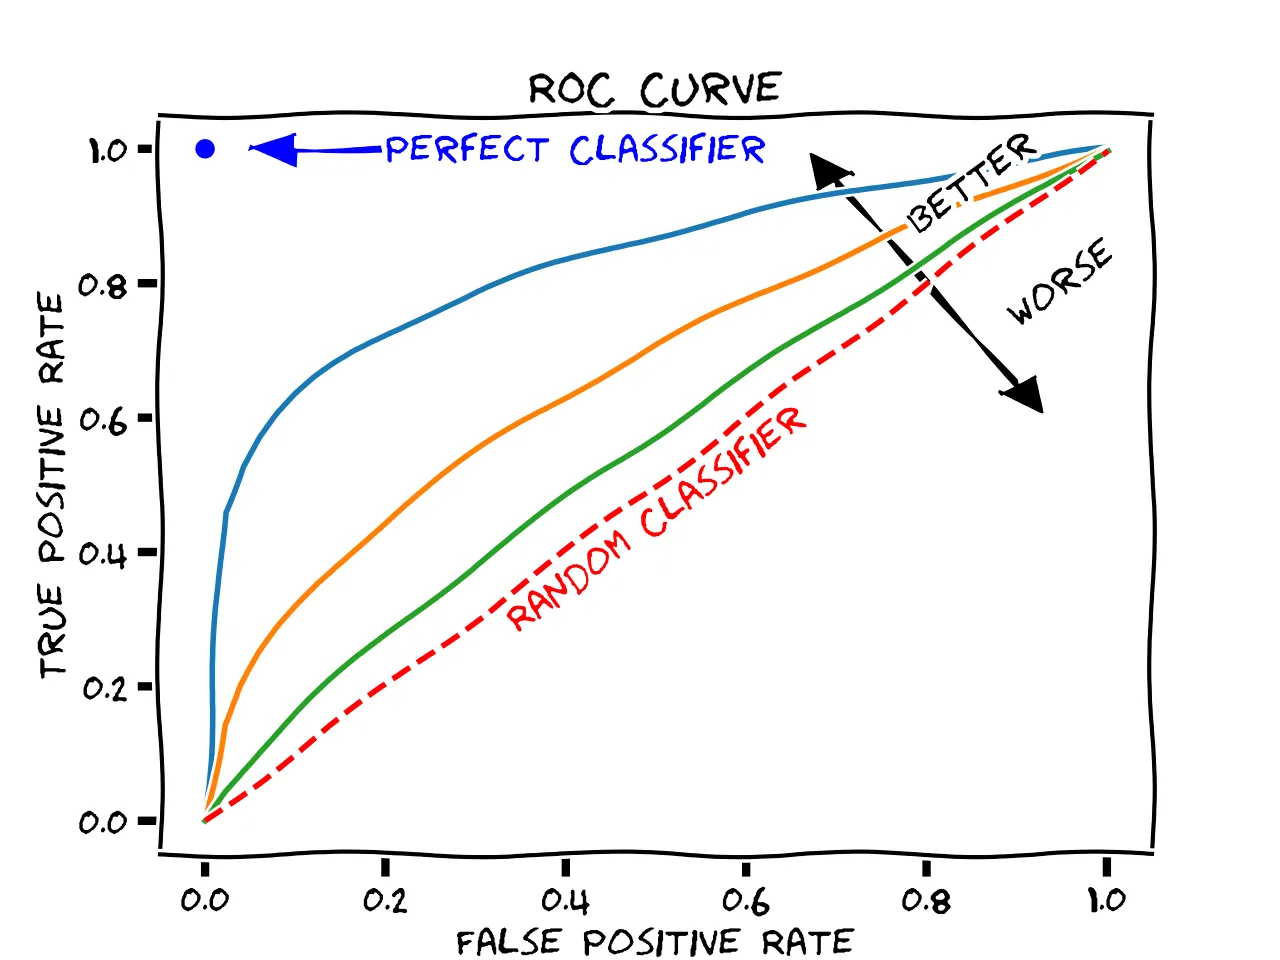

Suppose the operator must take a yes/no action (e.g., pre-release water) whenever $p_t \ge p^\ast$. For each threshold $p^\ast$ we get a 2×2 table, hence $(F, H)$; plotting $H$ against $F$ for all thresholds gives the **ROC curve**. The area under it (AUC) summarizes the curve:

| AUC | Meaning |
|---|---|
| $1$ | perfect discrimination — the best: some threshold gives $H = 1$ with $F = 0$ (curve hugs the top-left corner) |
| $0.5$ | no skill: the curve lies on the diagonal; every threshold gives $H = F$, as for random or constant forecasts |
| $< 0.5$ | worse than random; the forecast ranks non-events *above* events |
| $0$ | the worst: perfectly inverted ranking — but note that flipping such a forecast would make it perfect, so in practice AUC $< 0.5$ signals a sign error rather than a hopeless system |

ROC measures **discrimination only**: it depends on how well forecasts *rank* events vs non-events, not on whether the probabilities are calibrated.

#### Reading the ROC curve: one decision threshold = one point

The question is: **can we catch the event without issuing too many false alarms?**

Use the **same 40 years and the same above-normal inflow event** as in the reliability table. The event occurred in **14 years** and did not occur in **26 years**. These two totals stay fixed in every row below.

Suppose the operator takes action whenever the forecast probability is $p \ge p^\ast$. For example, $p^\ast = 0.50$ means “act when at least 10 of the 20 members predict above-normal inflow.” For each threshold, count the hits and false alarms, then calculate:

$$
x = F = \frac{\text{false alarms}}{26}, \qquad
y = H = \frac{\text{hits}}{14}.
$$

| Decision threshold, p* | Hits, a | False alarms, b | x: false alarm rate F | y: hit rate H |
|---|---:|---:|---:|---:|
| 1.01 (never act) | 0 | 0 | 0/26 = 0.00 | 0/14 = 0.00 |
| 0.90 | 1 | 0 | 0/26 = 0.00 | 1/14 = 0.07 |
| 0.85 | 2 | 0 | 0/26 = 0.00 | 2/14 = 0.14 |
| 0.80 | 4 | 0 | 0/26 = 0.00 | 4/14 = 0.29 |
| 0.75 | 4 | 1 | 1/26 = 0.04 | 4/14 = 0.29 |
| 0.70 | 5 | 2 | 2/26 = 0.08 | 5/14 = 0.36 |
| 0.65 | 6 | 2 | 2/26 = 0.08 | 6/14 = 0.43 |
| 0.55 | 6 | 3 | 3/26 = 0.12 | 6/14 = 0.43 |
| 0.50 | 7 | 3 | 3/26 = 0.12 | 7/14 = 0.50 |
| 0.45 | 9 | 3 | 3/26 = 0.12 | 9/14 = 0.64 |
| 0.40 | 9 | 6 | 6/26 = 0.23 | 9/14 = 0.64 |
| 0.35 | 10 | 8 | 8/26 = 0.31 | 10/14 = 0.71 |
| 0.30 | 12 | 10 | 10/26 = 0.38 | 12/14 = 0.86 |
| 0.25 | 12 | 11 | 11/26 = 0.42 | 12/14 = 0.86 |
| 0.20 | 12 | 13 | 13/26 = 0.50 | 12/14 = 0.86 |
| 0.15 | 12 | 17 | 17/26 = 0.65 | 12/14 = 0.86 |
| 0.10 | 13 | 21 | 21/26 = 0.81 | 13/14 = 0.93 |
| 0.05 | 14 | 24 | 24/26 = 0.92 | 14/14 = 1.00 |
| 0.00 | 14 | 26 | 26/26 = 1.00 | 14/14 = 1.00 |

This table gives every distinct threshold used for the **blue curve (`gamma=1`)** below, plus the “never act” starting point. The code also uses -0.01, which repeats the same **(1, 1)** endpoint as 0.00; that duplicate row is omitted here. The orange curve (`gamma=0.4`) uses a different set of forecast probabilities and has its own counts. Displayed coordinates are rounded; the code uses unrounded values.

**Work through the 0.50 row:** the operator acts in $7+3=10$ years. Of the 14 event years, **7 are caught and 7 are missed**, so $H=7/14=0.50$. Of the 26 non-event years, **3 produce false alarms and 23 do not**, so $F=3/26=0.12$. Plot the point **(0.12, 0.50)**.

Lowering the threshold to **0.30** catches **12 of 14 events** ($H=0.86$), but also raises false alarms to **10 of 26 non-events** ($F=0.38$). Lower thresholds mean more action: more events are caught, but more non-events can trigger action too. Connect the points as the threshold decreases to draw the ROC curve. The **top-left corner** means catching every event with no false alarms.

Two details matter:

- The ROC x-axis uses **false alarm rate**, $b/(b+d)$, not false alarm ratio, $b/(a+b)$. At the 0.50 threshold, these are $3/26=0.12$ and $3/10=0.30$, respectively.
- The **inflow threshold** (about 13.26 km³) defines the event and stays fixed. The **probability threshold** $p^\ast$ decides when to act and changes from row to row.

**Boundary convention:** both sections include the upper tercile boundary in “above normal” (`>=`), matching the category assignment in Part 4.1. This keeps the event definition identical in the two tables.

**Compare the tables:** reliability groups years with similar forecast probabilities and asks whether those probabilities match observed frequencies. ROC selects all years at or above each decision threshold and asks how many events and non-events trigger action. Reliability checks the probability values; ROC checks how well the forecasts separate events from non-events.


γ = 1.0 (calibrated)      AUC manual = 0.783   sklearn = 0.783   BSS = 0.249
γ = 0.4 (overconfident)   AUC manual = 0.729   sklearn = 0.729   BSS = 0.115


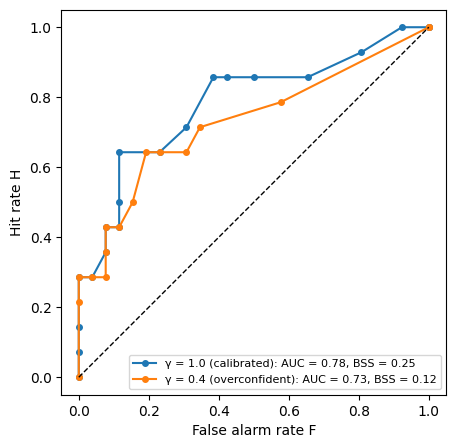

In [21]:
def roc_curve_manual(p, o):
    H, F = [], []
    for th in np.r_[1.01, np.unique(p)[::-1], -0.01]:
        yes = p >= th
        a_, b_ = np.sum(yes & (o == 1)), np.sum(yes & (o == 0))
        c_, d_ = np.sum(~yes & (o == 1)), np.sum(~yes & (o == 0))
        H.append(a_ / (a_ + c_)); F.append(b_ / (b_ + d_))
    H, F = np.array(H), np.array(F)
    trapz = getattr(np, 'trapezoid', None) or np.trapz   # name changed in numpy 2.0
    return F, H, trapz(H, F)

from sklearn.metrics import roc_auc_score
fig, ax = plt.subplots(figsize=(5, 5))
for g, lab in [(1.0, 'γ = 1.0 (calibrated)'), (0.4, 'γ = 0.4 (overconfident)')]:
    _, o_g, e_g = make_hindcast(gamma=g)
    tg = np.percentile(o_g, [100/3, 200/3])
    pg, og = (e_g >= tg[1]).mean(axis=1), (o_g >= tg[1]).astype(float)
    F_r, H_r, auc = roc_curve_manual(pg, og)
    bss_g = 1 - np.mean((pg - og)**2) / (og.mean() * (1 - og.mean()))
    ax.plot(F_r, H_r, 'o-', ms=4, label=f'{lab}: AUC = {auc:.2f}, BSS = {bss_g:.2f}')
    print(f'{lab:25s} AUC manual = {auc:.3f}   sklearn = {roc_auc_score(og, pg):.3f}   BSS = {bss_g:.3f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('False alarm rate F'); ax.set_ylabel('Hit rate H'); ax.set_aspect('equal'); ax.legend(fontsize=8)
plt.show()

> **Question:** The two systems have nearly the same AUC but different BSS. Which user cares about which score: an operator who acts on a fixed yes/no rule, or one who plugs the probabilities into an expected-value calculation?

### 4.4 Rank histogram and CRPS: is the whole ensemble consistent?

**Rank histogram** (Talagrand diagram): if the ensemble is statistically consistent with the observations, the observation's rank among the $M$ members is uniformly distributed. U-shape → under-dispersive (overconfident); dome → over-dispersive; slope → bias. The rank histogram is a *diagnostic*, not a score: the best outcome is a **flat** histogram (each of the $M+1$ ranks holds about $n/(M+1)$ observations), and the worst is all observations piled in the two outer bins (the observation always falls outside the ensemble).

**CRPS** stands for *Continuous Ranked Probability Score*. Read the name backwards: it is the *Ranked Probability Score* of Part 3, but for a *continuous* variable instead of three ordered categories. The RPS compared cumulative probabilities bin by bin; if you make the bins infinitely narrow, "cumulative probability at each bin" becomes the forecast CDF $F(x)$, the observation becomes a step function $H(x - y)$ (0 below the observed value, 1 above), and the sum becomes an integral:

$$
CRPS = \int_{-\infty}^{\infty} \big[F(x) - H(x - y)\big]^2\, dx
$$

i.e. the **squared area between the forecast CDF and the observation's step CDF**. For an ensemble of $M$ members, $F$ is the empirical CDF (a staircase with steps of $1/M$) and the integral has a closed form (Gneiting & Raftery, 2007):

$$
CRPS = \underbrace{\frac{1}{M}\sum_{m}|x_m - y|}_{\text{how far the members are from the observation}}
\;-\; \underbrace{\frac{1}{2M^2}\sum_{m}\sum_{k}|x_m - x_k|}_{\text{how spread out the members are}}
$$

**A worked example.** Three members $x = (10, 12, 15)$ km³, observation $y = 14$ km³.

| | Calculation | Value |
|---|---|---|
| Term 1: mean distance to observation | $(\lvert 10-14\rvert + \lvert 12-14\rvert + \lvert 15-14\rvert)/3 = (4 + 2 + 1)/3$ | 2.333 |
| Term 2: mean distance between members | pairs $\lvert 10-12\rvert, \lvert 10-15\rvert, \lvert 12-15\rvert = 2, 5, 3$; each counted twice: $2(2+5+3)/(2\cdot 3^2) = 20/18$ | 1.111 |
| **CRPS** | $2.333 - 1.111$ | **1.222 km³** |

The same number comes out of the area: the staircase CDF differs from the step by 1/3 on [10, 12], by 2/3 on [12, 14] and by 1/3 on [14, 15], so $(1/3)^2 \cdot 2 + (2/3)^2 \cdot 2 + (1/3)^2 \cdot 1 = 0.222 + 0.889 + 0.111 = 1.222$. The code cell below draws this.

Two things to notice:

- **The spread term is a reward**, not a penalty. Members that disagree lower the score, because spreading out is the honest thing to do when you are uncertain. But spreading out also pushes members away from the observation (term 1 grows), so the best CRPS is obtained at the *right* amount of spread — neither overconfident nor underconfident.
- **Units and the deterministic limit.** CRPS has the units of the variable (km³ here). With a single member, term 2 vanishes and term 1 is just $|x - y|$, so CRPS collapses to the **MAE**. In the example, issuing only the ensemble mean (12.33) would give $|12.33 - 14| = 1.67$ km³, worse than the ensemble's 1.22 km³: the spread information has value. This is what lets ensemble and ensemble-mean be compared on one scale.

**Range of values**

| Score | Best | Worst | Notes |
|---|---|---|---|
| $CRPS$ | 0 — every member equals the observation | $+\infty$ (no upper bound) | same units as the variable (km³ here); a single-member ensemble gives $CRPS = $ absolute error |
| $CRPSS = 1 - \overline{CRPS}/\overline{CRPS}_{clim}$ | 1 | $-\infty$ (no lower bound) | 0 = no better than the climatological ensemble (all other observed years); negative = worse |

Because CRPS has units, it is only comparable across variables or sites through the skill score; the next code cell reports both.


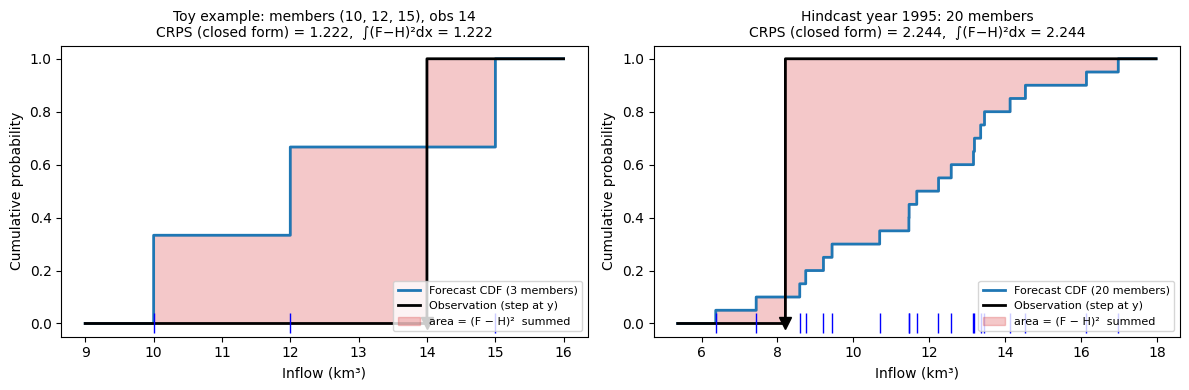

In [22]:
# CRPS as an area: the worked example above (left) and one real year of the hindcast (right)
def crps_cdf_plot(ax, members, y, title):
    x_m = np.sort(members); M = len(x_m)
    lo, hi = min(x_m.min(), y) - 1, max(x_m.max(), y) + 1
    grid = np.linspace(lo, hi, 2000)
    F = np.searchsorted(x_m, grid, side='right') / M            # ensemble empirical CDF
    H = (grid >= y).astype(float)                                 # observation step CDF
    ax.step(grid, F, where='post', color='tab:blue', lw=2, label=f'Forecast CDF ({M} members)')
    ax.step(grid, H, where='post', color='k', lw=2, label='Observation (step at y)')
    ax.fill_between(grid, F, H, step='post', color='tab:red', alpha=.25, label='area = (F − H)²  summed')
    ax.plot(x_m, np.zeros(M), 'b|', ms=14); ax.plot(y, 0, 'kv', ms=9)
    term1 = np.mean(np.abs(x_m - y)); term2 = np.mean(np.abs(x_m[:, None] - x_m[None, :])) / 2
    crps_val = term1 - term2                                      # closed form
    area = np.trapz((F - H)**2, grid)
    ax.set_title(f'{title}\nCRPS (closed form) = {crps_val:.3f},  ∫(F−H)²dx = {area:.3f}', fontsize=10)
    ax.set_xlabel('Inflow (km³)'); ax.set_ylabel('Cumulative probability'); ax.legend(fontsize=8, loc='lower right')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
crps_cdf_plot(axes[0], np.array([10.0, 12.0, 15.0]), 14.0, 'Toy example: members (10, 12, 15), obs 14')
yr = 10
crps_cdf_plot(axes[1], ens[yr], obs[yr], f'Hindcast year {years[yr]}: 20 members')
plt.tight_layout(); plt.show()


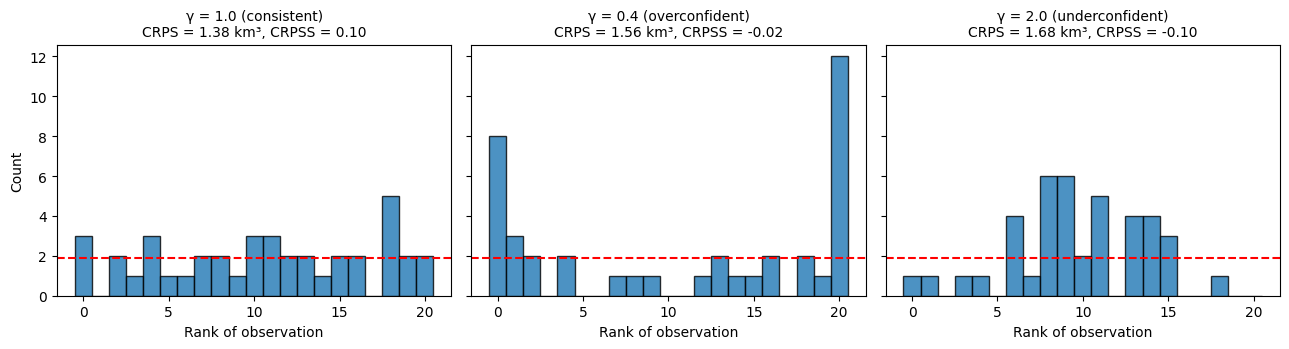

For reference, MAE of the ensemble mean (γ = 1.0): 1.94 km³


In [23]:
def crps_ensemble(ens, obs):
    t1 = np.mean(np.abs(ens - obs[:, None]), axis=1)
    t2 = 0.5 * np.mean(np.abs(ens[:, :, None] - ens[:, None, :]), axis=(1, 2))
    return t1 - t2

def crps_climatology(obs):
    '''Leave-one-out climatological ensemble: all *other* observed years.'''
    n = len(obs); idx = np.array([np.r_[0:i, i+1:n] for i in range(n)])
    return crps_ensemble(obs[idx], obs)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, g, lab in zip(axes, [1.0, 0.4, 2.0], ['γ = 1.0 (consistent)', 'γ = 0.4 (overconfident)', 'γ = 2.0 (underconfident)']):
    _, o_g, e_g = make_hindcast(gamma=g)
    ranks = np.sum(e_g < o_g[:, None], axis=1); M = e_g.shape[1]
    ax.hist(ranks, bins=np.arange(M + 2) - 0.5, edgecolor='k', alpha=.8); ax.axhline(len(o_g) / (M + 1), color='r', ls='--')
    crps_g = crps_ensemble(e_g, o_g).mean()
    ax.set_title(f'{lab}\nCRPS = {crps_g:.2f} km³, CRPSS = {1 - crps_g / crps_climatology(o_g).mean():.2f}', fontsize=10)
    ax.set_xlabel('Rank of observation')
axes[0].set_ylabel('Count'); plt.tight_layout(); plt.show()
print(f'For reference, MAE of the ensemble mean (γ = 1.0): {np.mean(np.abs(fmean - obs)):.2f} km³')

## Summary: one hindcast, many scores

Four forecast systems side by side. Note which scores move with skill (ρ), which move with calibration (γ), and which do not.

In [24]:
def verify_all(obs, ens):
    fm = ens.mean(axis=1)
    tc = np.percentile(obs, [100/3, 200/3]); oc, fc = np.digitize(obs, tc), np.digitize(fm, tc)
    ct = pd.crosstab(pd.Categorical(fc, [0,1,2]), pd.Categorical(oc, [0,1,2]), dropna=False)
    ec = np.digitize(ens, tc); pc = np.stack([(ec == k).mean(axis=1) for k in range(3)], 1); oh = np.eye(3)[oc]
    p, o = pc[:, 2], (oc == 2).astype(float)
    return pd.Series({
        'Pearson r': np.corrcoef(fm, obs)[0, 1],
        'SS_clim (MSE)': 1 - np.mean((fm - obs)**2) / np.mean((obs.mean() - obs)**2),
        'Heidke %': heidke_percent(np.trace(ct.values), len(obs)),
        'HSS': skill_multicat(ct)['HSS'],
        'RPSS': rpss(pc, oh),
        'BSS (above)': 1 - np.mean((p - o)**2) / (o.mean() * (1 - o.mean())),
        'AUC (above)': roc_auc_score(o, p),
        'CRPSS': 1 - crps_ensemble(ens, obs).mean() / crps_climatology(obs).mean()})

systems = {'No skill (ρ = 0)': dict(rho=0.0),
           'ρ = 0.6, overconfident (γ = 0.4)': dict(rho=0.6, gamma=0.4),
           'ρ = 0.6, calibrated': dict(rho=0.6),
           'ρ = 0.6, biased (β = +0.7)': dict(rho=0.6, beta=0.7),
           'ρ = 0.9, calibrated': dict(rho=0.9)}
pd.DataFrame({k: verify_all(*make_hindcast(**v)[1:]) for k, v in systems.items()}).T.round(2)

,Pearson r,SS_clim (MSE),Heidke %,HSS,RPSS,BSS (above),AUC (above),CRPSS
No skill (ρ = 0),-0.04,-0.06,-1.25,0.00,-0.03,0.01,0.59,0.02
"ρ = 0.6, overconfident (γ = 0.4)",0.44,0.15,10.00,0.10,-0.06,0.12,0.73,-0.02
"ρ = 0.6, calibrated",0.42,0.11,13.75,0.14,0.11,0.25,0.78,0.10
"ρ = 0.6, biased (β = +0.7)",0.42,-0.56,10.00,0.09,-0.17,-0.19,0.74,-0.22
"ρ = 0.9, calibrated",0.86,0.73,43.75,0.44,0.55,0.70,0.97,0.50


> **Question:** Which scores are blind to the bias in the fourth system? Which are blind to the overconfidence in the second? What does that tell you about reporting a single number?

## Practice
1. **Koka, probabilistic.** Turn the Koka deterministic forecast into tercile probabilities: regress $y$ on $\hat{y}$ in leave-one-year-out mode, use the residual standard deviation to define a normal predictive distribution for each year, and compute tercile probabilities from it. Then compute RPSS, the likelihood score and the Heidke score, and compare.
2. **Sampling uncertainty.** Verify the synthetic hindcast separately on years 1985–2004 and 2005–2024. How much do HSS, RPSS and BSS differ? Add a bootstrap 90 % interval for RPSS (resample years with replacement, 1000 times).
3. **Your own data.** Replace the synthetic hindcast with a real one (e.g., a leave-one-out regression hindcast of a Manitoba spring inflow from snow water equivalent or ENSO, with an ensemble built from the regression residuals) and run `verify_all` on it.

In [25]:
# Your code here

## References
- Wilks, D. S. (2011). *Statistical Methods in the Atmospheric Sciences*, 3rd ed., Chapter 8: Forecast Verification. Academic Press.
- Murphy, A. H. (1973). A new vector partition of the probability score. *J. Appl. Meteorol.*, 12, 595–600.
- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *J. Amer. Stat. Assoc.*, 102, 359–378.
- WWRP/WGNE Joint Working Group on Forecast Verification Research: [Forecast verification methods](https://www.cawcr.gov.au/projects/verification/).
- IRI: [Descriptions of the IRI climate forecast verification scores](https://iri.columbia.edu/wp-content/uploads/2013/07/scoredescriptions.pdf).